# 01 — Exploratory Data Analysis (MovieLens 1M)

**Goal:** Recommender banane se pehle data ko samajhna — sparsity, long-tail, rating bias, cold-start, aur ye decide karna ki split kaise karenge.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data import load_ratings, load_movies, load_users, leave_last_n_out

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
FIG = '../reports/figures/'

ratings, movies, users = load_ratings(), load_movies(), load_users()
df = ratings.merge(movies, on='movie_id').merge(users, on='user_id')
print(ratings.shape, movies.shape, users.shape)
ratings.head()

(1000209, 5) (3883, 5) (6040, 6)


,user_id,movie_id,rating,timestamp,datetime
0,1,1193,5,978300760,2000-12-31 22:12:40
1,1,661,3,978302109,2000-12-31 22:35:09
2,1,914,3,978301968,2000-12-31 22:32:48
3,1,3408,4,978300275,2000-12-31 22:04:35
4,1,2355,5,978824291,2001-01-06 23:38:11


## 1. Basic sanity checks

In [2]:
print('Missing values:'); print(ratings.isna().sum().to_string()); print()
print('Duplicate (user, movie) pairs:', ratings.duplicated(['user_id','movie_id']).sum())
print('Users:', ratings.user_id.nunique(), '| Movies rated:', ratings.movie_id.nunique(), '| Movies in catalog:', len(movies))
print('Date range:', ratings.datetime.min().date(), '->', ratings.datetime.max().date())

Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
datetime     0

Duplicate (user, movie) pairs: 0
Users: 6040 | Movies rated: 3706 | Movies in catalog: 3883
Date range: 2000-04-25 -> 2003-02-28


## 2. Rating distribution

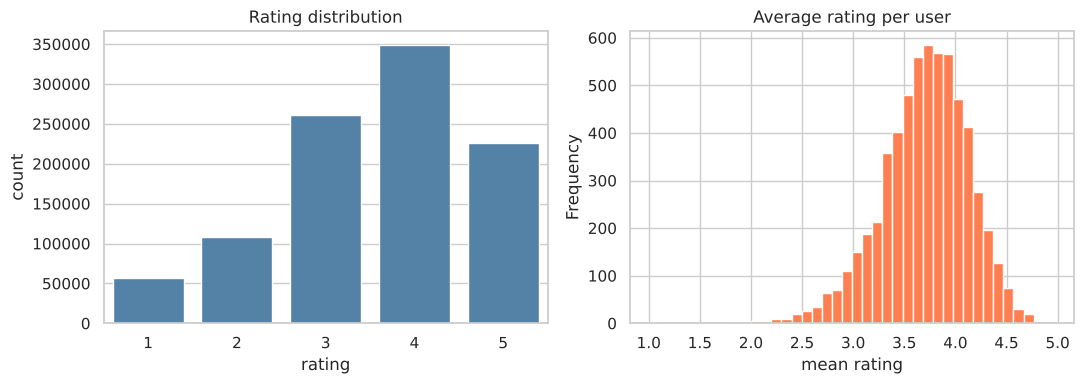

Global mean rating: 3.582


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='rating', data=ratings, ax=ax[0], color='steelblue')
ax[0].set_title('Rating distribution')
ratings.groupby('user_id').rating.mean().plot(kind='hist', bins=40, ax=ax[1], color='coral')
ax[1].set_title('Average rating per user'); ax[1].set_xlabel('mean rating')
plt.tight_layout(); plt.savefig(FIG+'01_rating_dist.png'); plt.show()
print('Global mean rating: %.3f' % ratings.rating.mean())

**Observation:** Ratings 4 sabse zyada hain aur average ~3.58 — log generally kaafi movies ko achha rate karte hain (positive bias). Alag-alag users ka average bahut alag hai, isliye model me **user bias** zaroori hoga (SVD me isiliye baseline terms hote hain).

## 3. Sparsity — recommender ki sabse badi problem

In [4]:
n_u, n_i, n_r = ratings.user_id.nunique(), ratings.movie_id.nunique(), len(ratings)
sparsity = 1 - n_r/(n_u*n_i)
print(f'Matrix size: {n_u} x {n_i} = {n_u*n_i:,} cells | Ratings: {n_r:,}')
print(f'Sparsity: {sparsity:.2%}  (density {1-sparsity:.2%})')

Matrix size: 6040 x 3706 = 22,384,240 cells | Ratings: 1,000,209
Sparsity: 95.53%  (density 4.47%)


Matrix ~95.5% khali hai. Isi wajah se simple methods fail hote hain aur matrix factorization jaise methods use karte hain.

## 4. Long-tail: kuch movies bahut popular, zyadatar kam

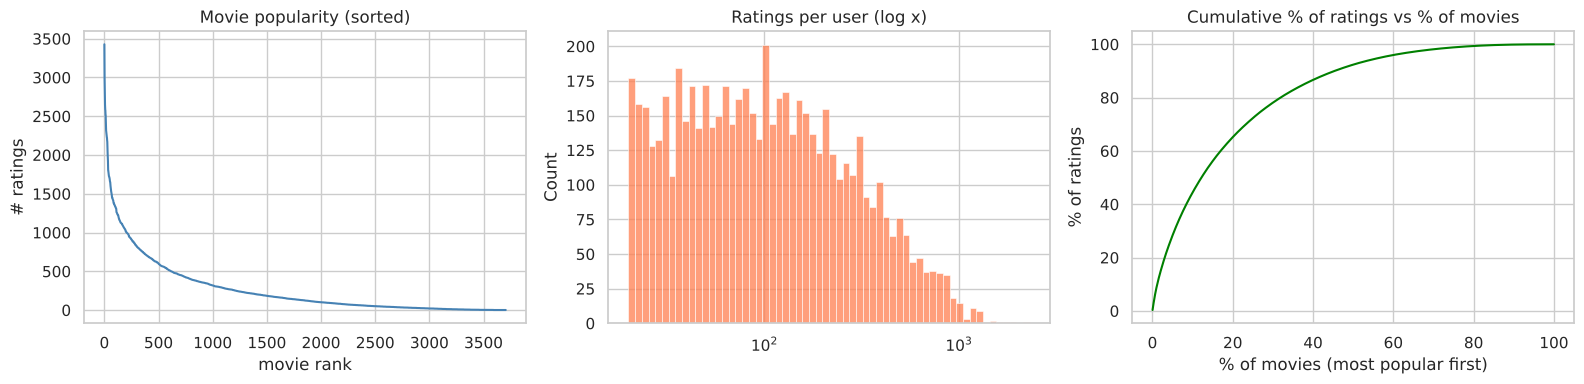

Top 20% movies cover 65.2% of all ratings
Movies with < 10 ratings: 446 (12.0% of rated movies)
Min / median / max ratings per user: 20 96.0 2314


In [5]:
item_cnt = ratings.groupby('movie_id').size().sort_values(ascending=False)
user_cnt = ratings.groupby('user_id').size()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(range(len(item_cnt)), item_cnt.values, color='steelblue')
ax[0].set_title('Movie popularity (sorted)'); ax[0].set_xlabel('movie rank'); ax[0].set_ylabel('# ratings')
sns.histplot(user_cnt, bins=60, log_scale=(True, False), ax=ax[1], color='coral')
ax[1].set_title('Ratings per user (log x)')
cum = item_cnt.cumsum()/item_cnt.sum()
ax[2].plot(np.arange(1, len(cum)+1)/len(cum)*100, cum.values*100, color='green')
ax[2].set_title('Cumulative % of ratings vs % of movies'); ax[2].set_xlabel('% of movies (most popular first)'); ax[2].set_ylabel('% of ratings')
plt.tight_layout(); plt.savefig(FIG+'02_long_tail.png'); plt.show()

top20 = (item_cnt.index[:int(0.2*len(item_cnt))])
print(f"Top 20% movies cover {item_cnt.loc[top20].sum()/item_cnt.sum():.1%} of all ratings")
print('Movies with < 10 ratings:', (item_cnt < 10).sum(), f'({(item_cnt<10).mean():.1%} of rated movies)')
print('Min / median / max ratings per user:', user_cnt.min(), user_cnt.median(), user_cnt.max())

**Observation:** Top 20% movies ~65% ratings cover karti hain. Isliye **popularity baseline** kaafi strong hoga, aur humara asli target **long-tail movies ko recommend karna** hona chahiye (coverage/novelty metrics yahin kaam aayenge). Har user ne kam se kam 20 ratings di hain, to user cold-start is dataset me nahi hai — usse hum alag se simulate karenge.

## 5. Top movies: popular vs highest rated (dono alag cheezein hain)

In [6]:
stats = ratings.groupby('movie_id').rating.agg(['count', 'mean']).join(movies.set_index('movie_id')[['title']])
print('Most rated:'); display(stats.sort_values('count', ascending=False).head(10))
print('Highest avg rating (min 100 ratings):'); display(stats[stats['count']>=100].sort_values('mean', ascending=False).head(10))
print('Highest avg rating WITHOUT min-count filter (misleading!):'); display(stats.sort_values('mean', ascending=False).head(5))

Most rated:


,count,mean,title
movie_id,,,
2858,3428,4.317386,American Beauty (1999)
260,2991,4.453694,Star Wars: Episode IV - A New Hope (1977)
1196,2990,4.292977,Star Wars: Episode V - The Empire Strikes Back...
1210,2883,4.022893,Star Wars: Episode VI - Return of the Jedi (1983)
480,2672,3.763847,Jurassic Park (1993)
2028,2653,4.337354,Saving Private Ryan (1998)
589,2649,4.058513,Terminator 2: Judgment Day (1991)
2571,2590,4.315830,"Matrix, The (1999)"
1270,2583,3.990321,Back to the Future (1985)


Highest avg rating (min 100 ratings):


,count,mean,title
movie_id,,,
2019,628,4.560510,Seven Samurai (The Magnificent Seven) (Shichin...
318,2227,4.554558,"Shawshank Redemption, The (1994)"
858,2223,4.524966,"Godfather, The (1972)"
745,657,4.520548,"Close Shave, A (1995)"
50,1783,4.517106,"Usual Suspects, The (1995)"
527,2304,4.510417,Schindler's List (1993)
1148,882,4.507937,"Wrong Trousers, The (1993)"
922,470,4.491489,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)
1198,2514,4.477725,Raiders of the Lost Ark (1981)


Highest avg rating WITHOUT min-count filter (misleading!):


,count,mean,title
movie_id,,,
3382,1,5.0,Song of Freedom (1936)
3172,1,5.0,Ulysses (Ulisse) (1954)
989,1,5.0,Schlafes Bruder (Brother of Sleep) (1995)
1830,1,5.0,Follow the Bitch (1998)
3656,1,5.0,Lured (1947)


**Observation:** Bina minimum-count filter ke, 1-2 ratings wali movies top par aa jati hain. Isliye ranking me **Bayesian/damped average** use karna chahiye (popularity baseline me hum ye karenge).

## 6. Genres

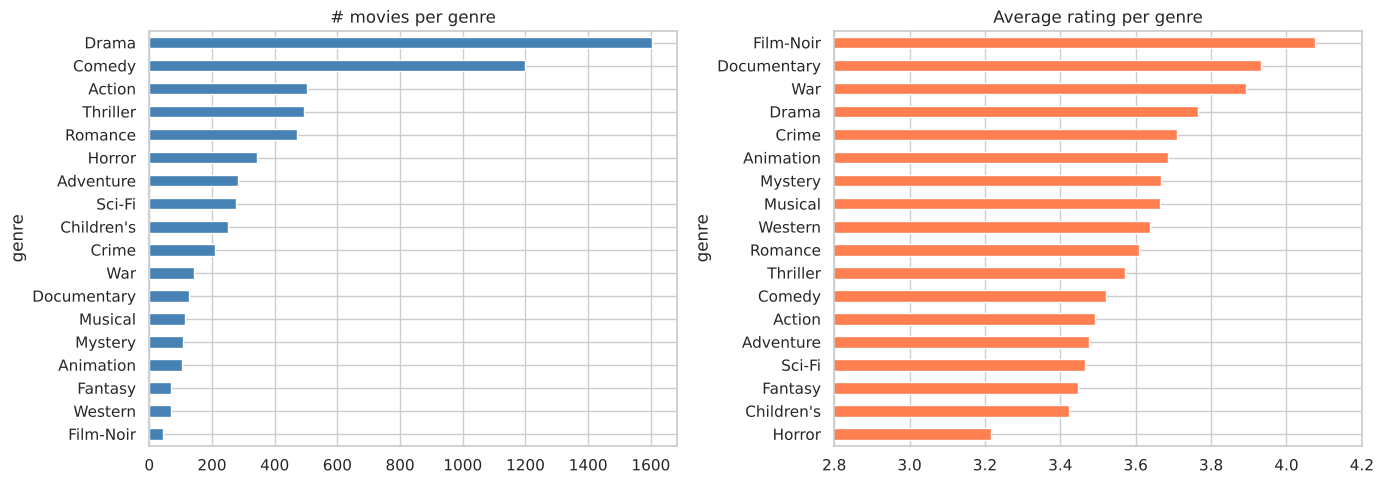

In [7]:
g = movies.explode('genre_list').rename(columns={'genre_list':'genre'})
genre_movies = g.groupby('genre').size().sort_values(ascending=False)
gr = ratings.merge(g[['movie_id','genre']], on='movie_id')
genre_stats = gr.groupby('genre').rating.agg(['count','mean']).sort_values('count', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
genre_movies.plot(kind='barh', ax=ax[0], color='steelblue').invert_yaxis(); ax[0].set_title('# movies per genre')
genre_stats['mean'].sort_values().plot(kind='barh', ax=ax[1], color='coral'); ax[1].set_title('Average rating per genre')
ax[1].set_xlim(2.8, 4.2)
plt.tight_layout(); plt.savefig(FIG+'03_genres.png'); plt.show()

## 7. Users: demographics

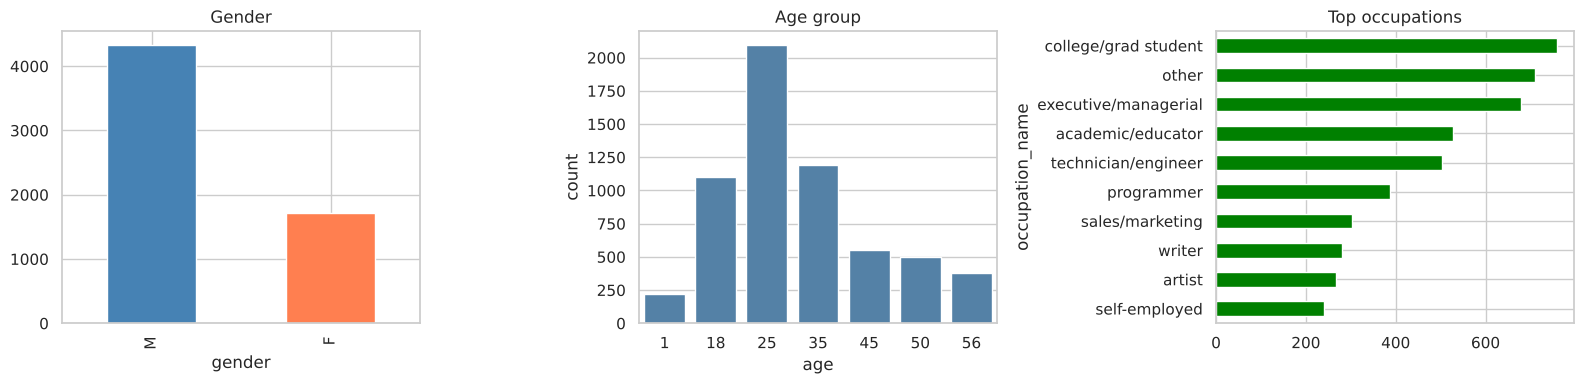

gender
F    3.620
M    3.569


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
users.gender.value_counts().plot(kind='bar', ax=ax[0], color=['steelblue','coral']); ax[0].set_title('Gender')
sns.countplot(x='age', data=users, ax=ax[1], color='steelblue'); ax[1].set_title('Age group')
users.occupation_name.value_counts().head(10).plot(kind='barh', ax=ax[2], color='green').invert_yaxis(); ax[2].set_title('Top occupations')
plt.tight_layout(); plt.savefig(FIG+'04_users.png'); plt.show()
print(df.groupby('gender').rating.mean().round(3).to_string())

## 8. Time — ratings kab di gayi?

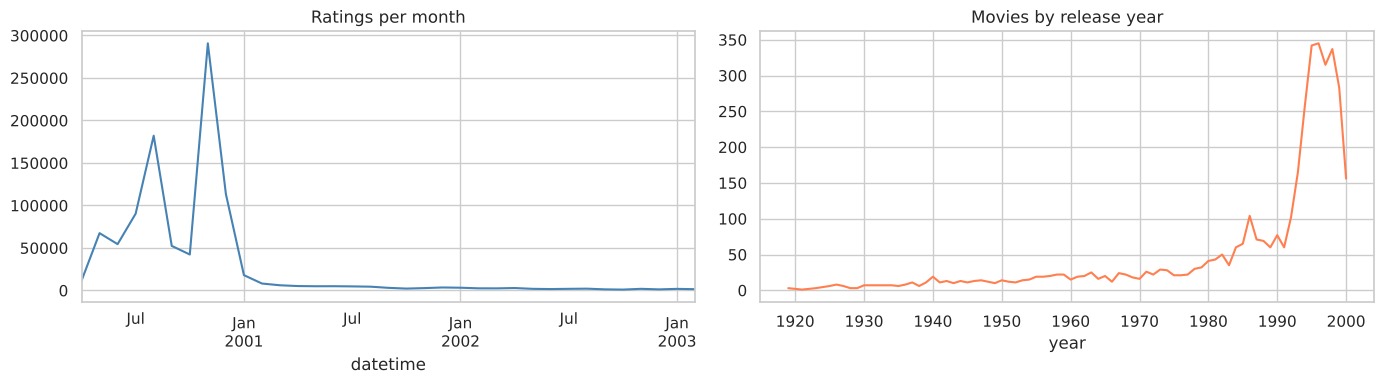

Share of ratings given in the year 2000: 90.5%


In [9]:
by_month = ratings.set_index('datetime').resample('ME').size()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_month.plot(ax=ax[0], color='steelblue'); ax[0].set_title('Ratings per month')
movies.year.dropna().astype(int).value_counts().sort_index().plot(ax=ax[1], color='coral'); ax[1].set_title('Movies by release year')
plt.tight_layout(); plt.savefig(FIG+'05_time.png'); plt.show()
print('Share of ratings given in the year 2000:', f'{(ratings.datetime.dt.year==2000).mean():.1%}')

**Observation:** Zyadatar ratings saal 2000 me aayi hain (data burst me collect hua). Phir bhi **per-user temporal split** sahi rahega — har user ki *latest* ratings test me jaayengi, bilkul real-world jaisa (past se future predict karna).

## 9. Train/test split — hum kaise karenge

In [10]:
train, val, test = leave_last_n_out(ratings, n_test=5, n_val=0)
print(f'train={len(train):,}  test={len(test):,}')
print('Every user in test also has history in train:', set(test.user_id) <= set(train.user_id))
print('Test movies unseen in train (item cold-start):', (~test.movie_id.isin(train.movie_id)).sum(), 'ratings')
print('Leakage check — max train ts <= min test ts per user:',
      (train.groupby('user_id').timestamp.max() <= test.groupby('user_id').timestamp.min()).all())

train=970,009  test=30,200
Every user in test also has history in train: True
Test movies unseen in train (item cold-start): 3 ratings
Leakage check — max train ts <= min test ts per user: True


## Key takeaways (README me daalne layak)
1. **Sparsity ~95.5%** → matrix factorization / neighbourhood methods chahiye, plain averaging nahi.
2. **Long-tail**: top 20% movies ≈ 65% ratings → popularity baseline strong; accuracy ke saath **coverage/novelty** bhi measure karenge.
3. **Rating bias** (user aur item dono) → baseline predictors / bias terms zaroori.
4. **Min-count filter** ke bina "best movies" ranking misleading → damped mean.
5. **Split**: per-user temporal leave-last-5-out (no leakage).
6. **Next (Week 2):** baselines — global mean, popularity, damped mean, user/item bias — aur evaluation functions.